In [33]:
import sys

scope_repo = "/Users/sergivela/Documents/SCOPE/Program/Scope"
sys.path.insert(0, f"{scope_repo}/core/src")
sys.path.insert(0, f"{scope_repo}/sco/src")

import scope
import scope_sco

In [34]:
import os
import csv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cosymlib
from scope.thermodynamics import get_Hvib, get_Svib


In [35]:
%run ./5a-Core_Ring_Map_Functions.ipynb

### Database

In [36]:
figures_path    = "/Users/sergivela/Documents/SCOPE/Database_SCO/Figures/"
env_path        = "/Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy"
root_path       = "/Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/1-Analyse_Database/"
outputs_path    = root_path + "Outputs/"
env             = scope.read_write.load_binary(env_path)
project_path    = "/Users/sergivela/Documents/SCOPE/Database_SCO/"

In [37]:
# Loads finished systems that are "unique" (i.e. non-repeated)
unique_csv_path     = outputs_path + "unique_systems.csv"

unique_systems = []
with open(unique_csv_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        sys = scope.read_write.load_binary(f"{project_path}/{row['path']}")
        sys.set_paths_from_environment(env)
        unique_systems.append(sys)

# All Unique TMCs

## Prepares Thermodynamic Data for all in "unique" 

In [38]:
thermo_unique_path = outputs_path + "unique_thermodynamic_data.csv"

In [ ]:
thermo_unique_line = [] # For Storage
dHelecs = []            # For easy access to values
dHvibs  = [] 
dSvibs  = [] 
dSelecs = [] 
dGtots  = [] 
T12s    = []

for sys in unique_systems:
    exists, this_branch = sys.find_branch('isolated')
    relative_path       = f"/Data/2-Systems/{sys.refcode}/{sys.refcode}.npy"

    # dHelec
    if 'dHelec' in this_branch.results.keys(): 
        dHelec = this_branch.results["dHelec"].value*scope.constants.har2kJmol
    else:
        dHelec = None
    dHelecs.append(float(dHelec))

    # dHvib
    if 'dHvib' in this_branch.results.keys(): 
        dHvib = this_branch.results["dHvib"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol
    else:
        dHvib = None
    dHvibs.append(float(dHvib))

    # dSvib
    if 'dSvib' in this_branch.results.keys(): 
        dSvib = this_branch.results["dSvib"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol*298
    else:
        dSvib = None
    dSvibs.append(float(dSvib))

    # dSelec
    if 'dSelec' in this_branch.results.keys(): 
        dSelec = this_branch.results["dSelec"].value*scope.constants.har2kJmol*298
    else:
        dSelec = None
    dSelecs.append(float(dSelec))

    # dGtot
    if 'dGtot' in this_branch.results.keys(): 
        dGtot = this_branch.results["dGtot"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol
    else:
        dGtot = None
    dGtots.append(float(dGtot))

    # T12
    if 'T12' in this_branch.results.keys(): 
        T12 = this_branch.results["T12"].value
        if T12 is None:   T12 = "None"
        elif T12 == "":   T12 = "None"
    else:
        T12 = "None"
    T12s.append(T12)

    # Denticity
    found, mol = sys.find_source("ref_hs_mol")
    if found:
        ligands = mol.ligands
        assert ligands is not None, f"Ligands not found in the reference molecule of {sys.refcode}."
        if all(lig.__eq__(ligands[0], with_graph=False) for lig in ligands):
            homoleptic = True
            if ligands[0].get_denticity()==1:    dent = int(1) 
            elif ligands[0].get_denticity()==2:  dent = int(2)
            elif ligands[0].get_denticity()==3:  dent = int(3)
            elif ligands[0].get_denticity()==6:  dent = int(6)
        else:
            homoleptic = False
            dent = "unknown"
    else:
        print(f"Reference molecule not found for {sys.refcode}. Cannot determine homolepticity or denticity.")
        homoleptic = "unknown"
        dent = "unknown"

    thermo_unique_line.append({"refcode": sys.refcode_wo_digits, "path": relative_path, "status": "finished", "dHelec[kJ/mol]": np.round(dHelec,6), "dHvib[kJ/mol](T=298K)": np.round(dHvib,6), "dSvib·T[kJ/mol](T=298K)": np.round(dSvib,6), "dSelec·T[kJ/mol](T=298K)": np.round(dSelec,6), "dGtot[kJ/mol](T=298K)": np.round(dGtot,6), "T12[K]": T12, "homoleptic": homoleptic, "denticity": dent}) 

with open(thermo_unique_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["refcode", "path", "status", "dHelec[kJ/mol]", "dHvib[kJ/mol](T=298K)", "dSvib·T[kJ/mol](T=298K)", "dSelec·T[kJ/mol](T=298K)", "dGtot[kJ/mol](T=298K)", "T12[K]", "homoleptic", "denticity"])
    writer.writeheader()
    writer.writerows(thermo_unique_line)


## Histograms

### dHelec

 /var/folders/w1/x1nrhk7x0kv5shx93_cwm79c0000gn/T/ipykernel_55482/682130030.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
 /opt/anaconda3/envs/scope_release_0.9.5/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


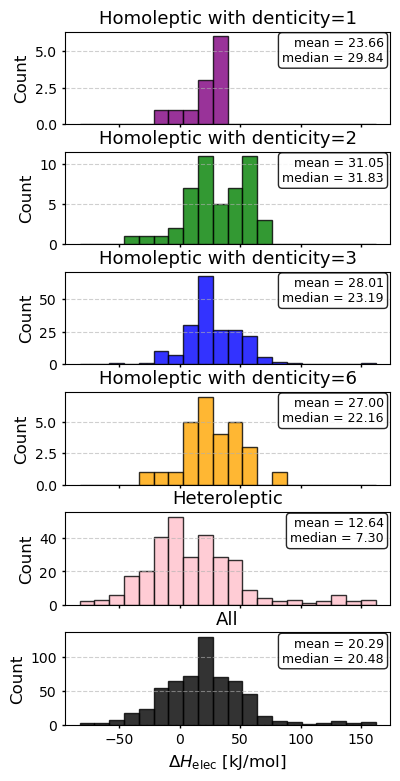

In [20]:
to_plot = get_values(thermo_unique_path, "dHelec[kJ/mol]") 

nbins = 20
xmin  = min(to_plot)
xmax  = max(to_plot)
if xmin == xmax: bins = [xmin - 0.5, xmax + 0.5]
else:
    bin_width = (xmax - xmin) / nbins
    bins = [xmin + i * bin_width for i in range(nbins + 1)]

# Plots dHelec histograms by denticity in homoleptic systems
fig, axs = plt.subplots(6, 1, figsize=(4.2, 9), tight_layout=True, sharex=True, gridspec_kw={'hspace': 0.3})

## Gets Values
dent1 = [float(entry["dHelec[kJ/mol]"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "1")]
dent2 = [float(entry["dHelec[kJ/mol]"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "2")]
dent3 = [float(entry["dHelec[kJ/mol]"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "3")]
dent6 = [float(entry["dHelec[kJ/mol]"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "6")]
other = [float(entry["dHelec[kJ/mol]"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "unknown")]
all_it = dent1 + dent2 + dent3 + dent6 + other

## Plots
for i in range(6):
    axs[i].tick_params(axis='both', which='major', length=2, width=1, direction='out')
    axs[i].tick_params(axis='both', which='minor', length=1, width=1, direction='out')
    axs[i].grid(axis='y', linestyle='--', alpha=0.6)
    axs[i].hist([dent1, dent2, dent3, dent6, other, all_it][i], bins=bins, color=[ 'purple', 'green', 'blue', 'orange', 'pink', 'black'][i], edgecolor='black', alpha=0.8)
    axs[i].set_ylabel("Count", fontsize=12)
    axs[i].text(0.98, 0.95, f"mean = {np.mean([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}\nmedian = {np.median([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}", transform=axs[i].transAxes, ha="right", va="top", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))
    if i < 4: axs[i].set_title(f"Homoleptic with denticity={['1', '2', '3', '6'][i]}", fontsize=13)
    elif i == 4:
        axs[i].set_title(f"Heteroleptic", fontsize=13)
    elif i == 5:
        axs[i].set_title(f"All", fontsize=13)
        axs[i].set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=12)

plt.savefig(figures_path + "dHelec_histogram_denticity.png", dpi=400)
plt.show()


### dSvib

 /var/folders/w1/x1nrhk7x0kv5shx93_cwm79c0000gn/T/ipykernel_55482/2164633363.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


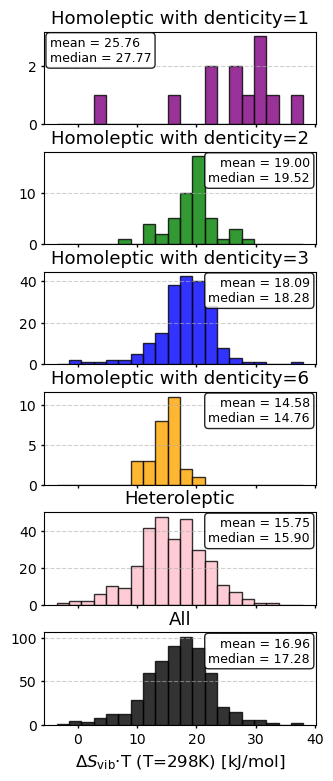

In [21]:
to_plot = get_values(thermo_unique_path, "dSvib·T[kJ/mol](T=298K)") 

nbins = 20
xmin  = min(to_plot)
xmax  = max(to_plot)
if xmin == xmax: bins = [xmin - 0.5, xmax + 0.5]
else:
    bin_width = (xmax - xmin) / nbins
    bins = [xmin + i * bin_width for i in range(nbins + 1)]

# Plots dSvib·T histograms by denticity in homoleptic systems
fig, axs = plt.subplots(6, 1, figsize=(3.5, 9), tight_layout=True, sharex=True, gridspec_kw={'hspace': 0.3})

## Gets Values
dent1 = [float(entry["dSvib·T[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "1")]
dent2 = [float(entry["dSvib·T[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "2")]
dent3 = [float(entry["dSvib·T[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "3")]
dent6 = [float(entry["dSvib·T[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "6")]
other = [float(entry["dSvib·T[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "unknown")]
all_it = dent1 + dent2 + dent3 + dent6 + other

## Plots
for i in range(6):
    axs[i].tick_params(axis='both', which='major', length=2, width=1, direction='out')
    axs[i].tick_params(axis='both', which='minor', length=1, width=1, direction='out')
    axs[i].grid(axis='y', linestyle='--', alpha=0.6)
    axs[i].hist([dent1, dent2, dent3, dent6, other, all_it][i], bins=bins, color=[ 'purple', 'green', 'blue', 'orange', 'pink', 'black'][i], edgecolor='black', alpha=0.8)
    #axs[i].set_ylabel("Count", fontsize=12)
    if i == 0: 
        axs[i].text(0.02, 0.95, f"mean = {np.mean([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}\nmedian = {np.median([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}", transform=axs[i].transAxes, ha="left", va="top", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))
    else: 
        axs[i].text(0.98, 0.95, f"mean = {np.mean([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}\nmedian = {np.median([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}", transform=axs[i].transAxes, ha="right", va="top", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))
    if i < 4: axs[i].set_title(f"Homoleptic with denticity={['1', '2', '3', '6'][i]}", fontsize=13)
    elif i == 4:
        axs[i].set_title(f"Heteroleptic", fontsize=13)
    elif i == 5:
        axs[i].set_title(f"All", fontsize=13)
        axs[i].set_xlabel(r"$\Delta S_{\mathrm{vib}}$·T (T=298K) [kJ/mol]", fontsize=12)

plt.savefig(figures_path + "dSvibT_histogram_denticity.png", dpi=400)
plt.show()

### dHvib

 /var/folders/w1/x1nrhk7x0kv5shx93_cwm79c0000gn/T/ipykernel_55482/87155805.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


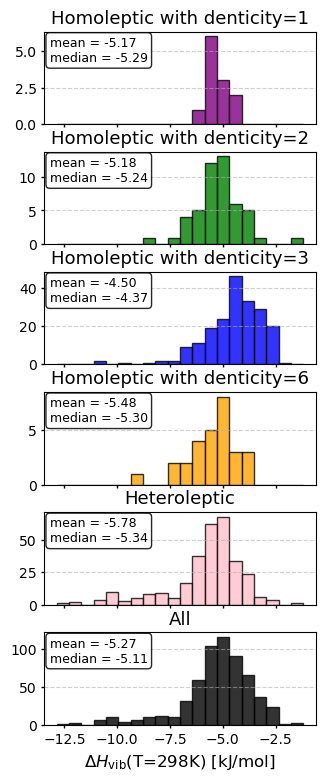

In [22]:
to_plot = get_values(thermo_unique_path, "dHvib[kJ/mol](T=298K)") 

nbins = 20
xmin  = min(to_plot)
xmax  = max(to_plot)
if xmin == xmax: bins = [xmin - 0.5, xmax + 0.5]
else:
    bin_width = (xmax - xmin) / nbins
    bins = [xmin + i * bin_width for i in range(nbins + 1)]

# Plots dHvib histograms by denticity in homoleptic systems
fig, axs = plt.subplots(6, 1, figsize=(3.5, 9), tight_layout=True, sharex=True, gridspec_kw={'hspace': 0.3})
    
## Gets Values
dent1 = [float(entry["dHvib[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "1")]
dent2 = [float(entry["dHvib[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "2")]
dent3 = [float(entry["dHvib[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "3")]
dent6 = [float(entry["dHvib[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "6")]
other = [float(entry["dHvib[kJ/mol](T=298K)"]) for entry in get_csv_entries(thermo_unique_path, "denticity", "unknown")]
all_it = dent1 + dent2 + dent3 + dent6 + other

## Plots
for i in range(6):
    axs[i].tick_params(axis='both', which='major', length=2, width=1, direction='out')
    axs[i].tick_params(axis='both', which='minor', length=1, width=1, direction='out')
    axs[i].grid(axis='y', linestyle='--', alpha=0.6)
    axs[i].hist([dent1, dent2, dent3, dent6, other, all_it][i], bins=bins, color=[ 'purple', 'green', 'blue', 'orange', 'pink', 'black'][i], edgecolor='black', alpha=0.8)
    #axs[i].set_ylabel("Count", fontsize=12)
    axs[i].text(0.02, 0.95, f"mean = {np.mean([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}\nmedian = {np.median([dent1, dent2, dent3, dent6, other, all_it][i]):.2f}", transform=axs[i].transAxes, ha="left", va="top", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))
    if i < 4: axs[i].set_title(f"Homoleptic with denticity={['1', '2', '3', '6'][i]}", fontsize=13)
    elif i == 4:
        axs[i].set_title(f"Heteroleptic", fontsize=13)
    elif i == 5:
        axs[i].set_title(f"All", fontsize=13)
        axs[i].set_xlabel(r"$\Delta H_{\mathrm{vib}}$(T=298K) [kJ/mol]", fontsize=12)

plt.savefig(figures_path + "dHvib_histogram_denticity.png", dpi=400)
plt.show()

### T12

 /var/folders/w1/x1nrhk7x0kv5shx93_cwm79c0000gn/T/ipykernel_55482/2624057913.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


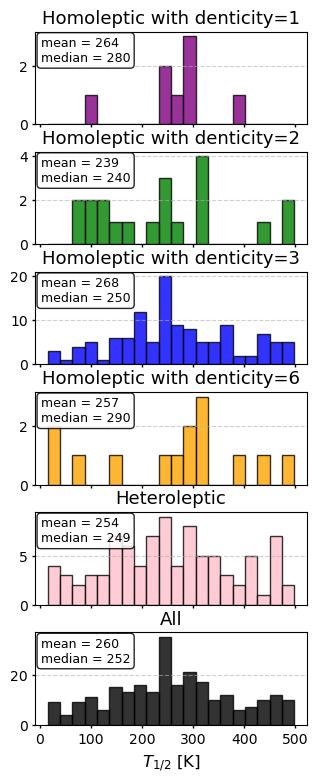

In [23]:
## Filters None T12 values
rows = filter_rows(thermo_unique_path, lambda row: row["T12[K]"] != "None")
to_plot = [float(row["T12[K]"]) for row in rows]

nbins = 20
xmin  = min(to_plot)
xmax  = max(to_plot)
if xmin == xmax: bins = [xmin - 0.5, xmax + 0.5]
else:
    bin_width = (xmax - xmin) / nbins
    bins = [xmin + i * bin_width for i in range(nbins + 1)]

# Plots T12 histograms by denticity in homoleptic systems
fig, axs = plt.subplots(6, 1, figsize=(3.5, 9), tight_layout=True, sharex=True, gridspec_kw={'hspace': 0.3})

## Gets Values
filtered = filter_rows(thermo_unique_path, lambda row: row["T12[K]"] != "None")
dent1    = [float(row["T12[K]"]) for row in rows if row["denticity"] == "1"]
dent2    = [float(row["T12[K]"]) for row in rows if row["denticity"] == "2"]
dent3    = [float(row["T12[K]"]) for row in rows if row["denticity"] == "3"]
dent6    = [float(row["T12[K]"]) for row in rows if row["denticity"] == "6"]
other    = [float(row["T12[K]"]) for row in rows if row["denticity"] == "unknown"]
all_it = dent1 + dent2 + dent3 + dent6 + other

## Plots
for i in range(6):
    axs[i].tick_params(axis='both', which='major', length=2, width=1, direction='out')
    axs[i].tick_params(axis='both', which='minor', length=1, width=1, direction='out')
    axs[i].grid(axis='y', linestyle='--', alpha=0.6)
    axs[i].hist([dent1, dent2, dent3, dent6, other, all_it][i], bins=bins, color=[ 'purple', 'green', 'blue', 'orange', 'pink', 'black'][i], edgecolor='black', alpha=0.8)
    #axs[i].set_ylabel("Count", fontsize=12)
    axs[i].text(0.02, 0.95, f"mean = {np.mean([dent1, dent2, dent3, dent6, other, all_it][i]):.0f}\nmedian = {np.median([dent1, dent2, dent3, dent6, other, all_it][i]):.0f}", transform=axs[i].transAxes, ha="left", va="top", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))
    if i < 4: axs[i].set_title(f"Homoleptic with denticity={['1', '2', '3', '6'][i]}", fontsize=13)
    elif i == 4:
        axs[i].set_title(f"Heteroleptic", fontsize=13)
    elif i == 5:
        axs[i].set_title(f"All", fontsize=13)
        axs[i].set_xlabel(r"$T_{1/2}$ [K]", fontsize=12)

plt.savefig(figures_path + "T12_histogram_denticity.png", dpi=400)
plt.show()

### Combined Histograms

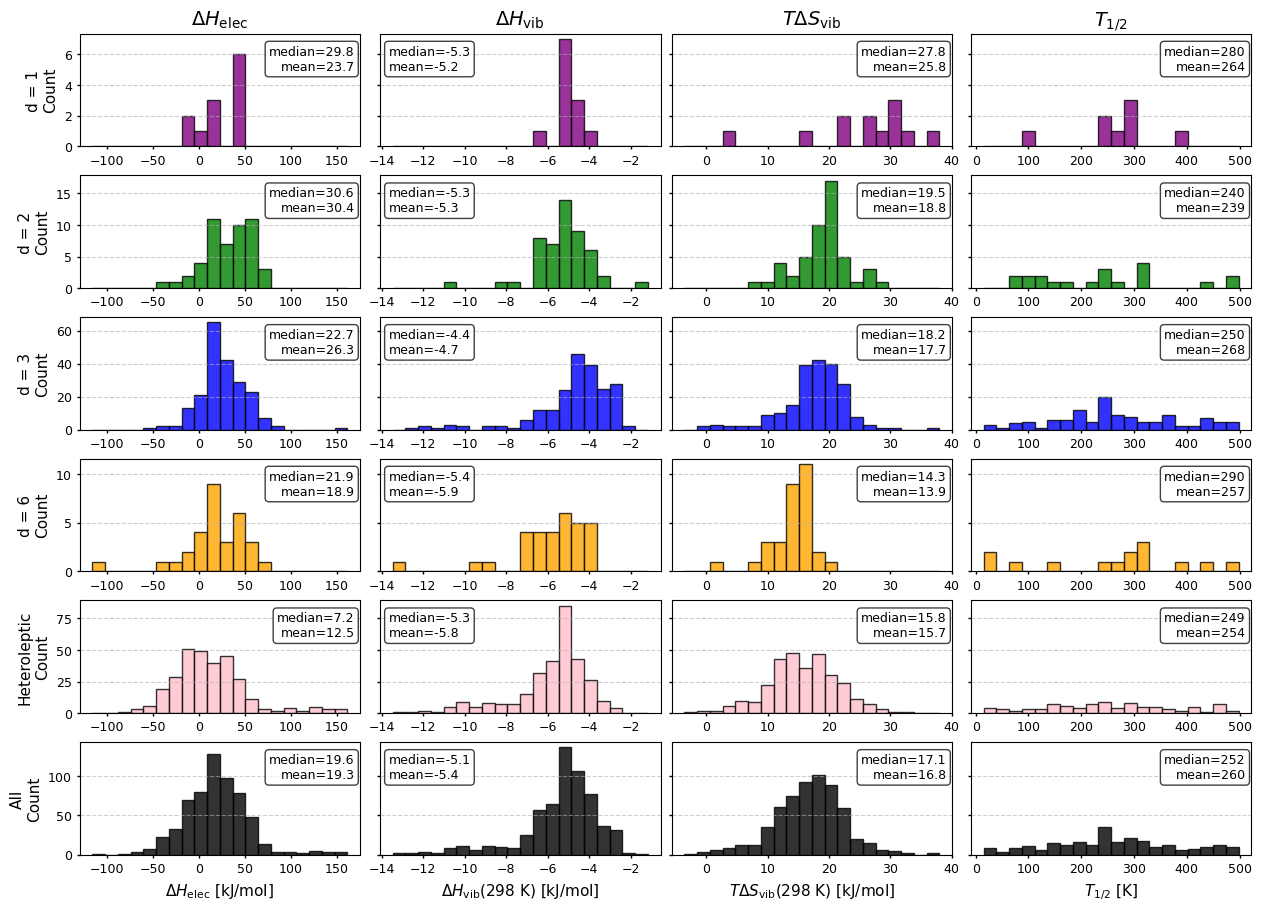

In [40]:
# Combined thermodynamic histograms by denticity

histogram_specs = [
    {
        "column": "dHelec[kJ/mol]",
        "xlabel": r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]",
        "title": r"$\Delta H_{\mathrm{elec}}$",
        "fmt": ".1f",
    },
    {
        "column": "dHvib[kJ/mol](T=298K)",
        "xlabel": r"$\Delta H_{\mathrm{vib}}$(298 K) [kJ/mol]",
        "title": r"$\Delta H_{\mathrm{vib}}$",
        "fmt": ".1f",
    },
    {
        "column": "dSvib·T[kJ/mol](T=298K)",
        "xlabel": r"$T\Delta S_{\mathrm{vib}}$(298 K) [kJ/mol]",
        "title": r"$T\Delta S_{\mathrm{vib}}$",
        "fmt": ".1f",
    },
    {
        "column": "T12[K]",
        "xlabel": r"$T_{1/2}$ [K]",
        "title": r"$T_{1/2}$",
        "fmt": ".0f",
        "filter": lambda row: row["T12[K]"] != "None",
    },
]

denticity_specs = [
    ("1", "d = 1", "purple"),
    ("2", "d = 2", "green"),
    ("3", "d = 3", "blue"),
    ("6", "d = 6", "orange"),
    ("unknown", "Heteroleptic", "pink"),
    ("all", "All", "black"),
]

nbins = 20
fig, axs = plt.subplots(
    len(denticity_specs), len(histogram_specs),
    figsize=(12.5, 9.0),
    constrained_layout=True,
    sharey="row",
)

for j, spec in enumerate(histogram_specs):
    rows = filter_rows(thermo_unique_path, spec.get("filter", lambda row: row[spec["column"]] != "None"))
    values_by_denticity = {
        denticity: [float(row[spec["column"]]) for row in rows if row["denticity"] == denticity]
        for denticity, _, _ in denticity_specs[:-1]
    }
    values_by_denticity["all"] = [
        value
        for denticity in values_by_denticity
        for value in values_by_denticity[denticity]
    ]

    to_plot = values_by_denticity["all"]
    xmin, xmax = min(to_plot), max(to_plot)
    if xmin == xmax:
        bins = [xmin - 0.5, xmax + 0.5]
    else:
        bin_width = (xmax - xmin) / nbins
        bins = [xmin + i * bin_width for i in range(nbins + 1)]

    for i, (denticity, row_label, color) in enumerate(denticity_specs):
        ax = axs[i, j]
        values = values_by_denticity[denticity]
        ax.hist(values, bins=bins, color=color, edgecolor="black", alpha=0.8)
        ax.tick_params(axis="both", which="major", length=2, width=1, direction="out", labelsize=9)
        ax.tick_params(axis="both", which="minor", length=1, width=1, direction="out")
        ax.grid(axis="y", linestyle="--", alpha=0.6)

        if j == 0:
            ax.set_ylabel(f"{row_label}\nCount", fontsize=11)
        if i == 0:
            ax.set_title(spec["title"], fontsize=14)
        if i == len(denticity_specs) - 1:
            ax.set_xlabel(spec["xlabel"], fontsize=11)

        if values:
            text_x = 0.03 if spec["column"] == "dHvib[kJ/mol](T=298K)" else 0.98
            text_ha = "left" if spec["column"] == "dHvib[kJ/mol](T=298K)" else "right"
            ax.text(
                text_x, 0.90,
                f"median={np.median(values):{spec['fmt']}}\n"
                f"mean={np.mean(values):{spec['fmt']}}",
                transform=ax.transAxes,
                ha=text_ha,
                va="top",
                fontsize=9,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.75),
            )

fig.savefig(figures_path + "TD_histograms_denticity.png", dpi=400)
plt.show()



## dHelec vs T

### Data extraction and fitting

In [41]:
filtered = filter_rows(thermo_unique_path, lambda row: row["T12[K]"] != "None")
h1 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "1"]
h2 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "2"]
h3 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "3"]
h6 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "6"]
ho = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "unknown"]
t1 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "1"]
t2 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "2"]
t3 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "3"]
t6 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "6"]
to = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "unknown"]

## Monodentate
coef1 = np.polyfit(h1, t1, 1)
x1_fit = np.linspace(min(h1), max(h1), 200)
y1_fit = coef1[0] * x1_fit + coef1[1]
r1 = 1 - np.sum((np.array(t1) - (coef1[0] * np.array(h1) + coef1[1])) ** 2) / np.sum((np.array(t1) - np.mean(t1)) ** 2)

## Bidentate
coef2  = np.polyfit(h2, t2, 1)
x2_fit = np.linspace(min(h2), max(h2), 200)
y2_fit = coef2[0] * x2_fit + coef2[1]
r2 = 1 - np.sum((np.array(t2) - (coef2[0] * np.array(h2) + coef2[1])) ** 2) / np.sum((np.array(t2) - np.mean(t2)) ** 2)

## Tridentate
coef3  = np.polyfit(h3, t3, 1)
x3_fit = np.linspace(min(h3), max(h3), 200)
y3_fit = coef3[0] * x3_fit + coef3[1]
r3 = 1 - np.sum((np.array(t3) - (coef3[0] * np.array(h3) + coef3[1])) ** 2) / np.sum((np.array(t3) - np.mean(t3)) ** 2)

## Hexadentate
coef6  = np.polyfit(h6, t6, 1)
x6_fit = np.linspace(min(h6), max(h6), 200)
y6_fit = coef6[0] * x6_fit + coef6[1]
r6 = 1 - np.sum((np.array(t6) - (coef6[0] * np.array(h6) + coef6[1])) ** 2) / np.sum((np.array(t6) - np.mean(t6)) ** 2)

## Heteroleptic
coefo  = np.polyfit(ho, to, 1)
xo_fit = np.linspace(min(ho), max(ho), 200)
yo_fit = coefo[0] * xo_fit + coefo[1]
ro = 1 - np.sum((np.array(to) - (coefo[0] * np.array(ho) + coefo[1])) ** 2) / np.sum((np.array(to) - np.mean(to)) ** 2)

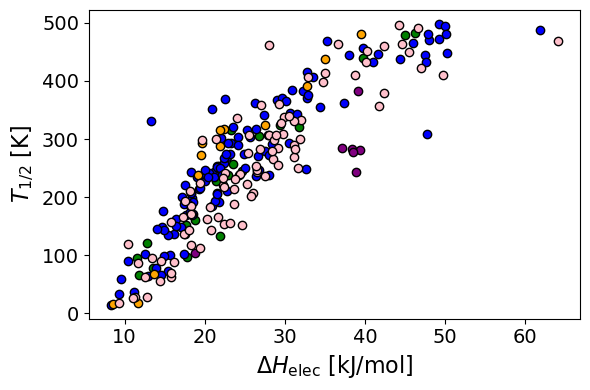

In [42]:
fig, ax = plt.subplots(figsize=(6, 4), tight_layout=True)
ax.scatter(h1, t1, color='purple', edgecolor='black')
ax.scatter(h2, t2, color='green', edgecolor='black')
ax.scatter(h3, t3, color='blue', edgecolor='black')
ax.scatter(h6, t6, color='orange', edgecolor='black')
ax.scatter(ho, to, color='pink', edgecolor='black')
ax.set_ylabel(r"$T_{1/2}$ [K]", fontsize=16)
ax.set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=14)
fig.savefig(figures_path + "T12_vs_dHelec_denticity_data.png", dpi=400)

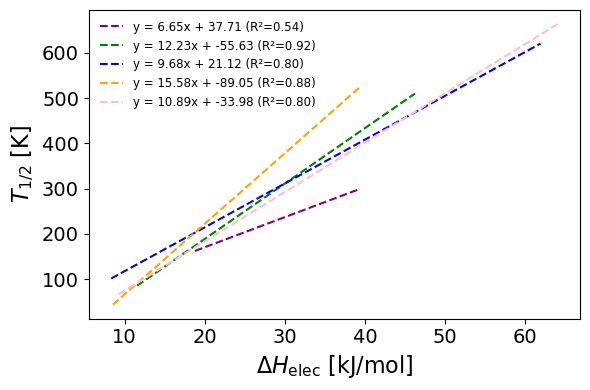

In [43]:
fig, ax = plt.subplots(figsize=(6, 4), tight_layout=True)
ax.plot(x1_fit, y1_fit, color='purple', linestyle='--', label=f'y = {coef1[0]:.2f}x + {coef1[1]:.2f} (R²={r1:.2f})')
ax.plot(x2_fit, y2_fit, color='green', linestyle='--',  label=f'y = {coef2[0]:.2f}x + {coef2[1]:.2f} (R²={r2:.2f})')
ax.plot(x3_fit, y3_fit, color='blue', linestyle='--',   label=f'y = {coef3[0]:.2f}x + {coef3[1]:.2f} (R²={r3:.2f})')
ax.plot(x6_fit, y6_fit, color='orange', linestyle='--', label=f'y = {coef6[0]:.2f}x + {coef6[1]:.2f} (R²={r6:.2f})')
ax.plot(xo_fit, yo_fit, color='pink', linestyle='--',   label=f'y = {coefo[0]:.2f}x + {coefo[1]:.2f} (R²={ro:.2f})')
ax.set_ylabel(r"$T_{1/2}$ [K]", fontsize=16)
ax.set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=16)
#ax.set_ylim(0,600)
#ax.set_xlim(0,70)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.legend(frameon=False, fontsize=8.5)
#ax.legend(loc="upper left", fontsize=10, frameon=False)
fig.savefig(figures_path + "T12_vs_dHelec_denticity_fit.png", dpi=400)

## SCO Able

In [32]:
# Thermodynamic ranges compatible with a SCO transition between 250 and 350 K

sco_t12_min = 250.0
sco_t12_max = 350.0

thermo_columns = {
    "dHelec[kJ/mol]": "dHelec[kJ/mol]",
    "dHvib[kJ/mol]": "dHvib[kJ/mol](T=298K)",
    "T*dSvib[kJ/mol]": "dSvib·T[kJ/mol](T=298K)",
}

def safe_float(value):
    if value in (None, "", "None", "nan", "NaN"):
        return None
    return float(value)

sco_rows = []
with open(thermo_unique_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        t12 = safe_float(row.get("T12[K]"))
        if t12 is not None and sco_t12_min <= t12 <= sco_t12_max:
            sco_rows.append(row)

compatible_ranges = []
for label, column in thermo_columns.items():
    values = np.array([safe_float(row[column]) for row in sco_rows], dtype=float)
    compatible_ranges.append({
        "quantity": label,
        "n": len(values),
        "min": round(np.min(values), 2),
        "max": round(np.max(values), 2),
        "p10": round(np.percentile(values, 10), 2),
        "p90": round(np.percentile(values, 90), 2),
        "median": round(np.median(values), 2),
    })

print(f"SCO-compatible window: {len(sco_rows)} systems with {sco_t12_min:.0f} <= T1/2 <= {sco_t12_max:.0f} K")
compatible_ranges


SCO-compatible window: 72 systems with 250 <= T1/2 <= 350 K


[{'quantity': 'dHelec[kJ/mol]',
  'n': 72,
  'min': np.float64(13.33),
  'max': np.float64(47.7),
  'p10': np.float64(21.65),
  'p90': np.float64(31.82),
  'median': np.float64(26.7)},
 {'quantity': 'dHvib[kJ/mol]',
  'n': 72,
  'min': np.float64(-7.3),
  'max': np.float64(-2.55),
  'p10': np.float64(-6.21),
  'p90': np.float64(-2.95),
  'median': np.float64(-4.6)},
 {'quantity': 'T*dSvib[kJ/mol]',
  'n': 72,
  'min': np.float64(5.37),
  'max': np.float64(38.0),
  'p10': np.float64(13.41),
  'p90': np.float64(22.91),
  'median': np.float64(18.37)}]

## Frequency-Resolved Vibrational Contributions

The HS--LS vibrational entropy and enthalpy differences are decomposed into the same frequency windows at 298.15 K. Both quantities are evaluated with the SCOPE harmonic-oscillator functions, `get_Svib` and `get_Hvib`, and stored in a shared CSV cache.

In [6]:
TEMPERATURE = 298.15
MIN_FREQ_CM = 1.0
FREQ_BINS_CM = np.array([1, 10, 50, 100, 200, 400, 800, 1600, 4000], dtype=float)
DENTICITIES_TO_COMPARE = ['1', '2', '3', '6']
ENTROPY_METHOD = 'scope.thermodynamics.get_Svib(default harmonic oscillator, abs freqs, >=1 cm-1)'
ENTHALPY_METHOD = 'scope.thermodynamics.get_Hvib(default harmonic oscillator, abs freqs, >=1 cm-1)'


def get_hs_ls_b3lyp_states(system):
    found_hs, hs_mol = system.find_source('ref_hs_mol')
    found_ls, ls_mol = system.find_source('ref_ls_mol')
    if not (found_hs and found_ls):
        raise ValueError('Missing HS or LS reference molecule')

    found_hs_state, hs_state = hs_mol.find_state('b3lyp_opt')
    found_ls_state, ls_state = ls_mol.find_state('b3lyp_opt')
    if not (found_hs_state and found_ls_state):
        raise ValueError('Missing HS or LS b3lyp_opt state')
    return hs_state, ls_state


def thermal_frequencies_cm(state):
    freqs = np.abs(np.asarray(state.freqs_cm, dtype=float))
    return freqs[freqs >= MIN_FREQ_CM]


def binned_vibrational_values(freqs_cm):
    entropy = []
    enthalpy = []
    for low, high in zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:]):
        bin_freqs = freqs_cm[(freqs_cm >= low) & (freqs_cm < high)]
        entropy.append(1000 * get_Svib(bin_freqs, TEMPERATURE, freq_units='cm', outunits='kj').value)
        enthalpy.append(get_Hvib(bin_freqs, TEMPERATURE, freq_units='cm', outunits='kj').value)
    return np.asarray(entropy), np.asarray(enthalpy)

In [7]:
overwrite = False
vibrational_bins_path = outputs_path + 'unique_vibrational_data_bins.csv'
required_columns = {
    'refcode', 'denticity', 'homoleptic', 'bin_low[cm-1]', 'bin_high[cm-1]',
    'bin_label[cm-1]', 'HS_Svib[J·mol-1·K-1]', 'LS_Svib[J·mol-1·K-1]',
    'dSvib[J·mol-1·K-1]', 'HS_Hvib[kJ·mol-1]', 'LS_Hvib[kJ·mol-1]',
    'dHvib[kJ·mol-1]',
}

with open(thermo_unique_path, newline='') as f:
    thermo_by_refcode = {row.get('refcode', row.get('id')): row for row in csv.DictReader(f)}
expected_refcodes = set(thermo_by_refcode)

if os.path.exists(vibrational_bins_path) and not overwrite:
    vibrational_bin_df = pd.read_csv(vibrational_bins_path)
    if required_columns - set(vibrational_bin_df.columns):
        print('The cached table does not contain both vibrational terms; rebuilding it.')
        overwrite = True
    elif set(vibrational_bin_df['refcode']) != expected_refcodes:
        print('The cached table does not match the current unique-system set; rebuilding it.')
        overwrite = True
    else:
        print(f'Loaded {len(vibrational_bin_df)} frequency-bin rows from {vibrational_bins_path}')

if overwrite or not os.path.exists(vibrational_bins_path):
    vibrational_bin_rows = []
    failures = []

    for system in unique_systems:
        refcode = system.refcode_wo_digits
        try:
            thermo_row = thermo_by_refcode[refcode]
            hs_state, ls_state = get_hs_ls_b3lyp_states(system)
            hs_entropy, hs_enthalpy = binned_vibrational_values(thermal_frequencies_cm(hs_state))
            ls_entropy, ls_enthalpy = binned_vibrational_values(thermal_frequencies_cm(ls_state))

            for i, (low, high) in enumerate(zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:])):
                vibrational_bin_rows.append({
                    'refcode': refcode,
                    'denticity': thermo_row['denticity'],
                    'homoleptic': thermo_row['homoleptic'] == 'True',
                    'temperature[K]': TEMPERATURE,
                    'entropy_method': ENTROPY_METHOD,
                    'enthalpy_method': ENTHALPY_METHOD,
                    'bin_low[cm-1]': low,
                    'bin_high[cm-1]': high,
                    'bin_label[cm-1]': f'{int(low)}-{int(high)}',
                    'HS_Svib[J·mol-1·K-1]': hs_entropy[i],
                    'LS_Svib[J·mol-1·K-1]': ls_entropy[i],
                    'dSvib[J·mol-1·K-1]': hs_entropy[i] - ls_entropy[i],
                    'HS_Hvib[kJ·mol-1]': hs_enthalpy[i],
                    'LS_Hvib[kJ·mol-1]': ls_enthalpy[i],
                    'dHvib[kJ·mol-1]': hs_enthalpy[i] - ls_enthalpy[i],
                })
        except Exception as exc:
            failures.append((refcode, repr(exc)))

    vibrational_bin_df = pd.DataFrame(vibrational_bin_rows)
    vibrational_bin_df.to_csv(vibrational_bins_path, index=False)
    print(f'Wrote {len(vibrational_bin_df)} frequency-bin rows to {vibrational_bins_path}')
    print(f'Failures: {len(failures)}')
    if failures:
        print(failures[:10])

The cached table does not contain both vibrational terms; rebuilding it.


Wrote 4832 frequency-bin rows to /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/1-Analyse_Database/Outputs/unique_vibrational_data_bins.csv
Failures: 0


In [8]:
# FEPHAK is excluded because its ligand-composition descriptor cannot be generated.
homoleptic_bin_df = vibrational_bin_df[
    vibrational_bin_df['homoleptic'].astype(str).str.lower().eq('true')
    & vibrational_bin_df['denticity'].astype(str).isin(DENTICITIES_TO_COMPARE)
    & (vibrational_bin_df['refcode'] != 'FEPHAK')
].copy()
homoleptic_bin_df['denticity'] = homoleptic_bin_df['denticity'].astype(str)

ordered = [d for d in DENTICITIES_TO_COMPARE if d in set(homoleptic_bin_df['denticity'])]
bin_order = [f'{int(low)}-{int(high)}' for low, high in zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:])]


def mean_bin_pivot(value_column):
    return (
        homoleptic_bin_df
        .groupby(['denticity', 'bin_label[cm-1]'], sort=False)[value_column]
        .mean()
        .unstack()
        .reindex(index=ordered, columns=bin_order)
    )


def plot_frequency_contributions(pivot, xlabel, output_name):
    fig, ax = plt.subplots(figsize=(7.2, 3.4), tight_layout=True)
    colors = ['#4C1D95', '#2563EB', '#0891B2', '#16A34A', '#FACC15', '#F97316', '#DC2626', '#DB2777']
    y_pos = np.arange(len(pivot))
    left_pos = np.zeros(len(pivot))
    left_neg = np.zeros(len(pivot))

    for label, color in zip(pivot.columns, colors):
        values = pivot[label].fillna(0).to_numpy()
        positive = np.where(values > 0, values, 0)
        negative = np.where(values < 0, values, 0)
        ax.barh(y_pos, positive, left=left_pos, color=color, edgecolor='white', linewidth=0.6, label=f'{label} cm$^{{-1}}$')
        ax.barh(y_pos, negative, left=left_neg, color=color, edgecolor='white', linewidth=0.6)
        left_pos += positive
        left_neg += negative

    ax.set_yticks(y_pos, [f'd={d}' for d in pivot.index])
    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.9)
    ax.legend(title='Frequency window', frameon=False, fontsize=8, title_fontsize=9, bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='x', alpha=0.25)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.0)
    fig.savefig(figures_path + output_name, dpi=400)
    plt.show()

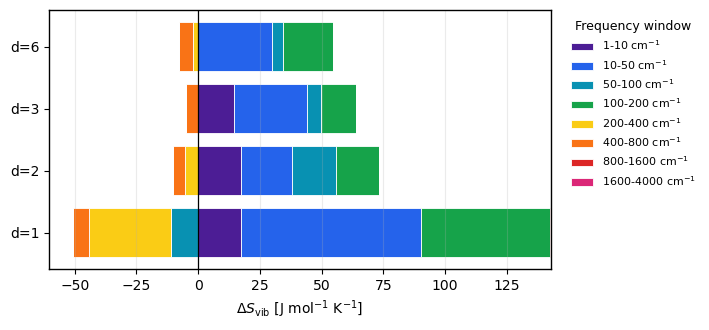

In [9]:
dSvib_pivot = mean_bin_pivot('dSvib[J·mol-1·K-1]')
plot_frequency_contributions(
    dSvib_pivot,
    r'$\Delta S_{\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]',
    'dSvib_binned_contribution.png',
)

**Caption.** Mean frequency-resolved contribution to $Delta S_{mathrm{vib}}$ for each denticity. Each horizontal bar decomposes the average HS--LS vibrational entropy change into frequency windows; positive segments indicate regions where the HS state contributes more entropy than the LS state.

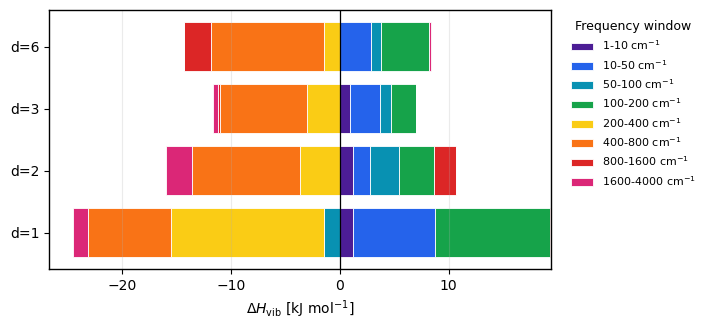

In [10]:
dHvib_pivot = mean_bin_pivot('dHvib[kJ·mol-1]')
plot_frequency_contributions(
    dHvib_pivot,
    r'$\Delta H_{\mathrm{vib}}$ [kJ mol$^{-1}$]',
    'dHvib_binned_contribution.png',
)

**Caption.** Mean frequency-resolved contribution to $Delta H_{mathrm{vib}}$ for each denticity, using the same frequency windows as the entropy decomposition. Positive and negative segments indicate frequency regions that respectively increase or decrease the HS--LS vibrational enthalpy difference.